<a href="https://colab.research.google.com/github/lanaorlova/My_firt_test_Repo/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%962.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

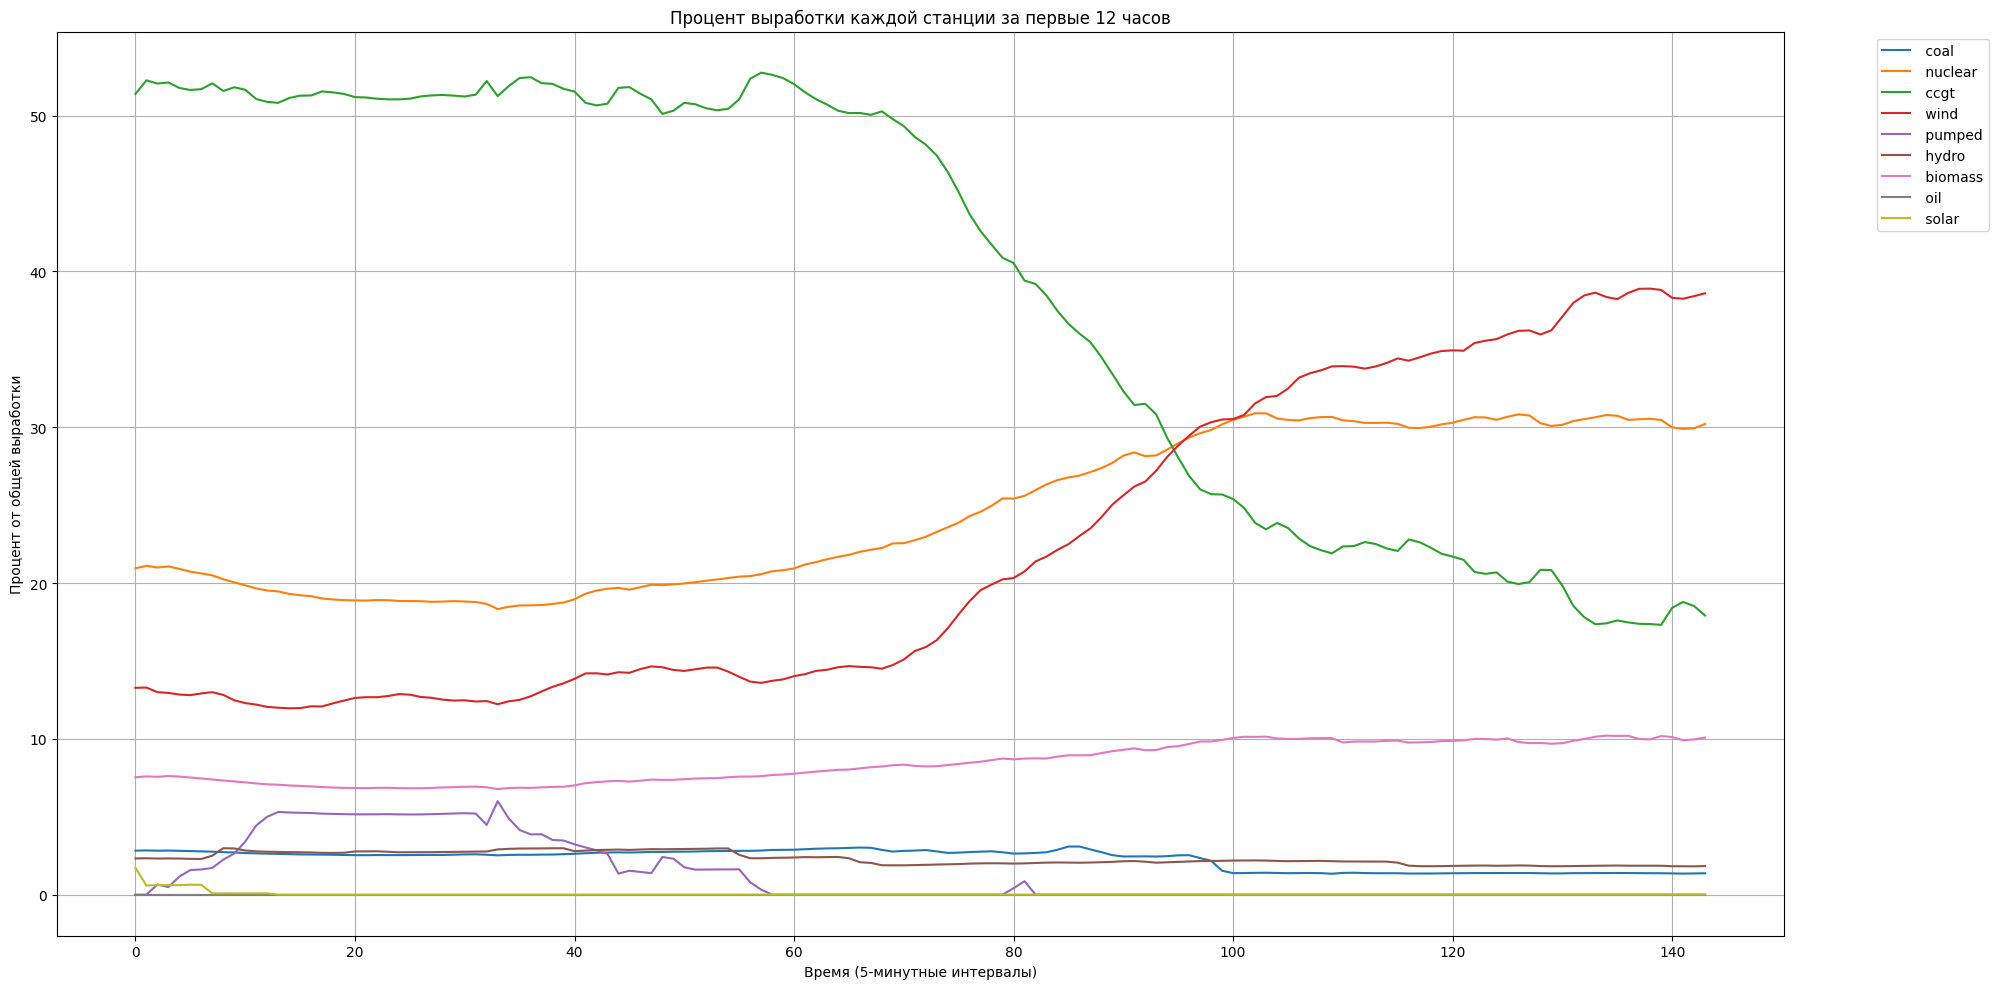

In [ ]:
# Импорт необходимых библиотек
import pandas as pd
import matplotlib.pyplot as plt
from bokeh.plotting import figure, output_notebook, show

# Получение и чтение данных
url = "https://drive.google.com/uc?export=download&id=18VeFLUIj22hRmc_tNGjfoawyn7iyqQ_w"
input_df = pd.read_csv(url, sep=',')

# Преобразование числовых столбцов
numeric_cols = input_df.columns[2:]
for col in numeric_cols:
    input_df[col] = pd.to_numeric(input_df[col], errors='coerce')

# Взять данные за первые 12 часов (144 записи)
data = input_df.iloc[:144]
generation_columns = data.columns[2:]

# Вычисление суммарной выработки и процентного вклада
total_generation = data[generation_columns].sum(axis=1)
percentage_df = data[generation_columns].div(total_generation, axis=0) * 100

# График с Matplotlib
plt.figure(figsize=(20, 10))
for column in percentage_df.columns:
    plt.plot(percentage_df.index, percentage_df[column], label=column)

plt.xlabel('Время (5-минутные интервалы)')
plt.ylabel('Процент от общей выработки')
plt.title('Процент выработки каждой станции за первые 12 часов')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.savefig('generation_percentage.png')
plt.show()

# Сохранение данных в Excel
percentage_df.to_excel('generation_percentage.xlsx')

# Интерактивный график с Bokeh
output_notebook()
p = figure(width=800, height=400,
           title='Процент выработки каждой станции за первые 12 часов',
           x_axis_label='Время (5-минутные интервалы)',
           y_axis_label='Процент от общей выработки')

colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'cyan']
for i, column in enumerate(percentage_df.columns):
    p.line(percentage_df.index, percentage_df[column],
           line_width=2, color=colors[i], legend_label=column)

p.legend.location = "top_left"
p.legend.click_policy = "hide"
show(p)
